# Matplotlib 1/3 : Premiers graphiques (`plot` et `scatter`)

**Objectifs** : tracer des courbes (`plot`) et des nuages de points (`scatter`), les annoter (titres, étiquettes, légende) et les sauvegarder.

*Durée estimée : 35 min.*

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

## 1. Le principe : figure et axes

Matplotlib organise un graphique en deux objets :

- la **figure** (`fig`) : la « feuille » entière
- les **axes** (`ax`) : la zone de tracé, avec ses graduations, son titre, etc.

On les crée toujours de la même manière avec `plt.subplots()`, puis on dessine **sur `ax`**. C'est la façon recommandée de travailler : elle se généralise facilement à plusieurs graphiques.

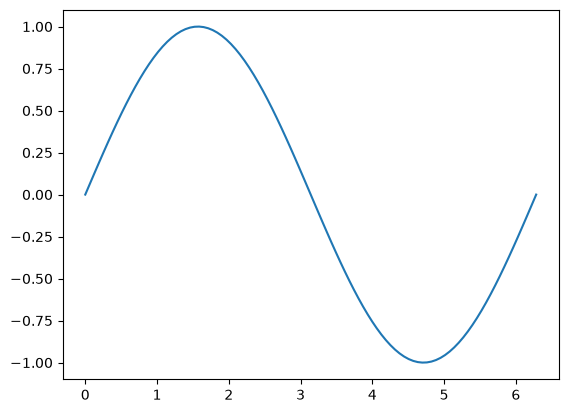

In [4]:
x = np.linspace(0, 2 * np.pi, 100)
y = np.sin(x)

fig, ax = plt.subplots()
ax.plot(x, y)
plt.show()

## 2. Titres, étiquettes, grille

**Un graphique sans titre ni légende d'axes est un graphique incomplet.** Les méthodes sont préfixées par `set_` :

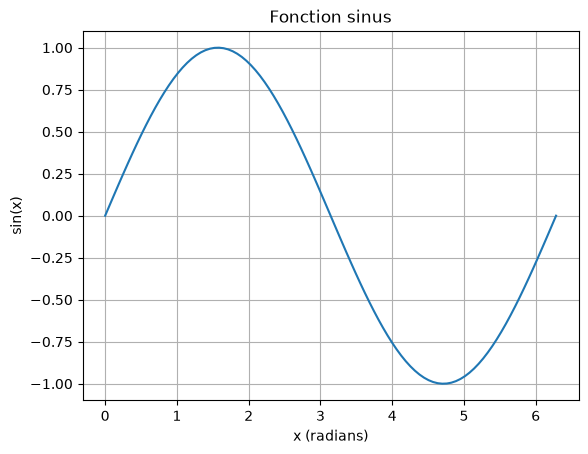

In [5]:
fig, ax = plt.subplots()
ax.plot(x, y)
ax.set_title("Fonction sinus")
ax.set_xlabel("x (radians)")
ax.set_ylabel("sin(x)")
ax.grid(True)
plt.show()

## 3. Plusieurs courbes et légende

On appelle `ax.plot` plusieurs fois, en donnant un `label` à chaque courbe, puis `ax.legend()`.

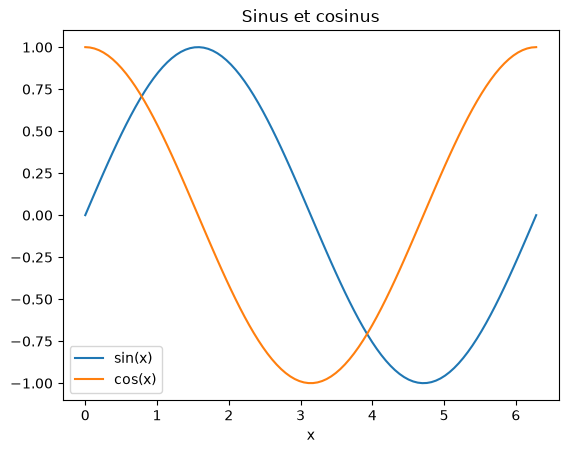

In [6]:
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), label="sin(x)")
ax.plot(x, np.cos(x), label="cos(x)")
ax.set_title("Sinus et cosinus")
ax.set_xlabel("x")
ax.legend()
plt.show()

## 4. Style des courbes

| Option | Exemples |
|---|---|
| `color` | `"red"`, `"tab:blue"`, `"#2a9d8f"` |
| `linestyle` (ou `ls`) | `"-"`, `"--"`, `":"`, `"-."` |
| `linewidth` (ou `lw`) | `1`, `2.5` |
| `marker` | `"o"`, `"s"`, `"^"`, `"x"` |
| `alpha` | transparence entre 0 et 1 |

Il existe aussi une notation compacte : `"r--"` = rouge, tirets.

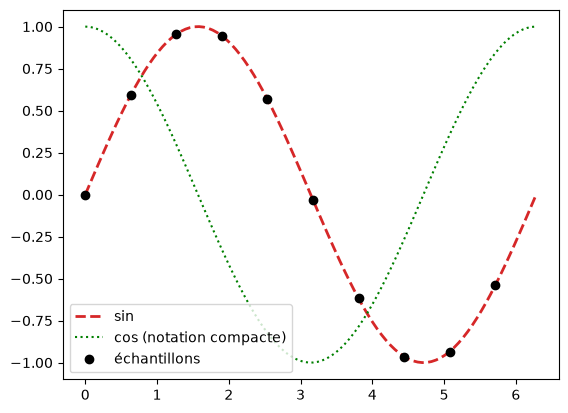

In [7]:
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), color="tab:red", linestyle="--", linewidth=2, label="sin")
ax.plot(x, np.cos(x), "g:", label="cos (notation compacte)")
ax.plot(x[::10], np.sin(x[::10]), "ko", label="échantillons")   # points seulement
ax.legend()
plt.show()

### Tracer des données « réelles » : les points ne sont pas toujours reliés par une fonction

Quand `x` n'est pas régulier, `plot` relie les points dans l'ordre fourni. Ajouter `marker="o"` aide à voir les vraies mesures.

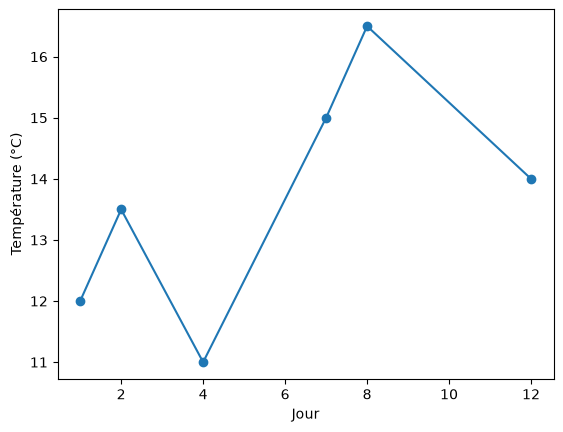

In [8]:
jours = [1, 2, 4, 7, 8, 12]
temp = [12.0, 13.5, 11.0, 15.0, 16.5, 14.0]

fig, ax = plt.subplots()
ax.plot(jours, temp, marker="o")
ax.set_xlabel("Jour")
ax.set_ylabel("Température (°C)")
plt.show()

## 5. Nuage de points : `scatter`

`scatter(x, y)` dessine un point par couple `(x, y)`. Contrairement à `plot`, les points ne sont **pas reliés**, et on peut faire varier leur **taille** (`s`) et leur **couleur** (`c`).

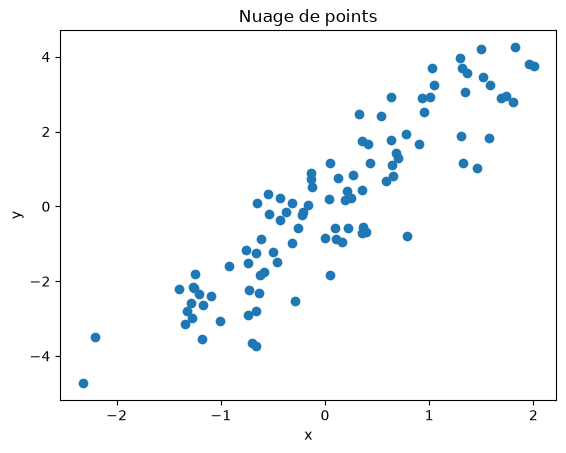

In [9]:
rng = np.random.default_rng(0)
x = rng.normal(size=100)
y = 2 * x + rng.normal(size=100)

fig, ax = plt.subplots()
ax.scatter(x, y)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Nuage de points")
plt.show()

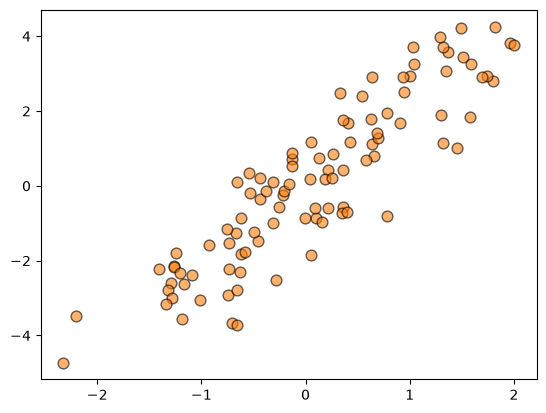

In [10]:
fig, ax = plt.subplots()
ax.scatter(x, y, s=60, c="tab:orange", alpha=0.6, edgecolor="black")
plt.show()

`alpha` (transparence) est très utile quand beaucoup de points se superposent.

## 6. Avec un DataFrame

On passe simplement des colonnes comme `x` et `y`. Voici le Titanic : l'âge et le tarif des passagers (les âges manquants sont ignorés).

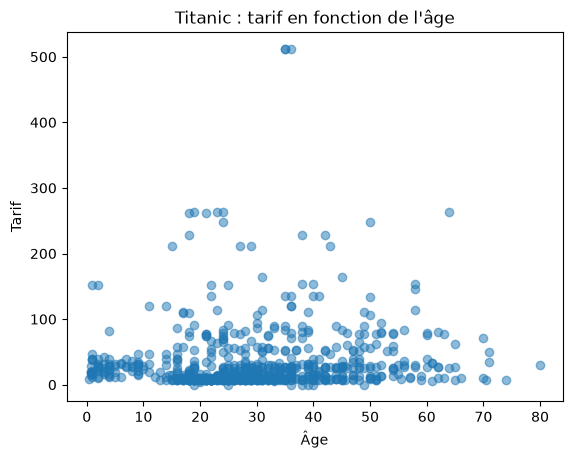

In [11]:
df = pd.read_csv("../data/titanic.csv")

fig, ax = plt.subplots()
ax.scatter(df["Age"], df["Fare"], alpha=0.5)
ax.set_xlabel("Âge")
ax.set_ylabel("Tarif")
ax.set_title("Titanic : tarif en fonction de l'âge")
plt.show()

Pour comparer deux groupes, on appelle `scatter` **une fois par groupe**, avec un `label` :

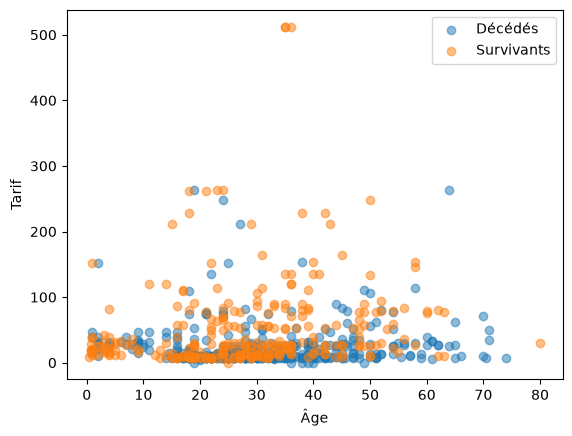

In [12]:
surv = df[df["Survived"] == 1]
mort = df[df["Survived"] == 0]

fig, ax = plt.subplots()
ax.scatter(mort["Age"], mort["Fare"], alpha=0.5, label="Décédés")
ax.scatter(surv["Age"], surv["Fare"], alpha=0.5, label="Survivants")
ax.set_xlabel("Âge")
ax.set_ylabel("Tarif")
ax.legend()
plt.show()

Et pour les courbes, un exemple avec le fichier de températures mensuelles (valeurs moyennes approximatives, à titre d'illustration) :

In [13]:
temp = pd.read_csv("../data/temperatures.csv")
temp.head(3)

,Mois,Paris,Lyon,Marseille
0,Jan,5.0,4.0,7.5
1,Fév,5.5,5.5,8.5
2,Mar,8.5,9.5,11.5


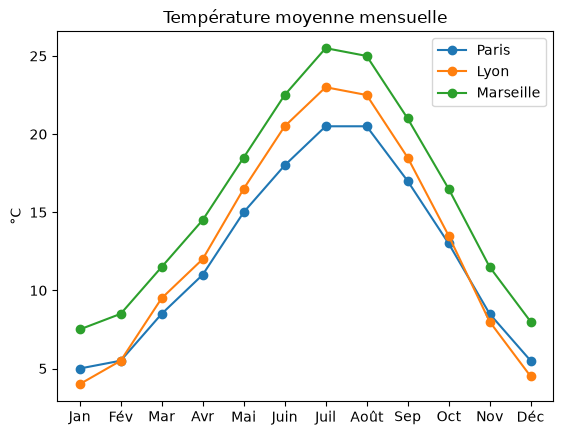

In [14]:
fig, ax = plt.subplots()
for ville in ["Paris", "Lyon", "Marseille"]:
    ax.plot(temp["Mois"], temp[ville], marker="o", label=ville)
ax.set_title("Température moyenne mensuelle")
ax.set_ylabel("°C")
ax.legend()
plt.show()

## 7. Sauvegarder une figure

`fig.savefig(...)` écrit un fichier image (PNG, PDF, SVG… selon l'extension). À appeler **avant** `plt.show()` en script ; dans un notebook, ça marche aussi après.

In [15]:
fig.savefig("temperatures.png", dpi=150, bbox_inches="tight")

## Récapitulatif

| Je veux… | Code |
|---|---|
| créer figure et axes | `fig, ax = plt.subplots()` |
| courbe | `ax.plot(x, y, label="...")` |
| nuage de points | `ax.scatter(x, y, s=..., c=..., alpha=...)` |
| titre, axes | `ax.set_title`, `ax.set_xlabel`, `ax.set_ylabel` |
| légende, grille | `ax.legend()`, `ax.grid(True)` |
| sauvegarder | `fig.savefig("fichier.png")` |

---
## Exercices

### ✏️ Exercice 1

Tracez la parabole `y = x²` pour `x` entre -3 et 3 (100 points), avec un titre, des étiquettes d'axes et une grille.

<function matplotlib.pyplot.show(close=None, block=None)>

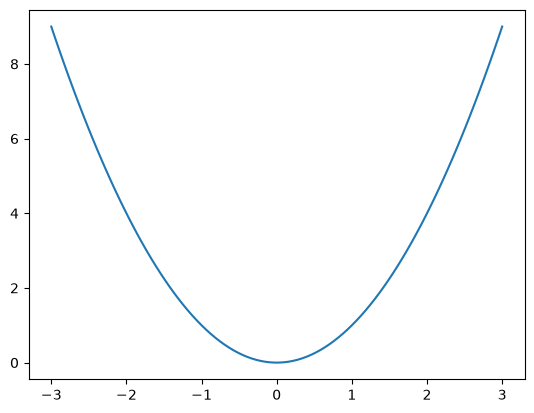

In [17]:
# Votre code ici
X = np.linspace(-3, 3, 100)
Y = X ** 2
fig, ax = plt.subplots()
ax.plot(X, Y)
plt.show

<details>
<summary>💡 Voir la solution</summary>

```python
x = np.linspace(-3, 3, 100)
fig, ax = plt.subplots()
ax.plot(x, x**2)
ax.set_title("Parabole")
ax.set_xlabel("x")
ax.set_ylabel("x²")
ax.grid(True)
plt.show()
```

</details>

### ✏️ Exercice 2

Sur un même graphique, tracez `exp(-x)` en rouge pointillé et `exp(-2x)` en bleu plein, pour `x` de 0 à 5. Ajoutez une légende.

<function matplotlib.pyplot.show(close=None, block=None)>

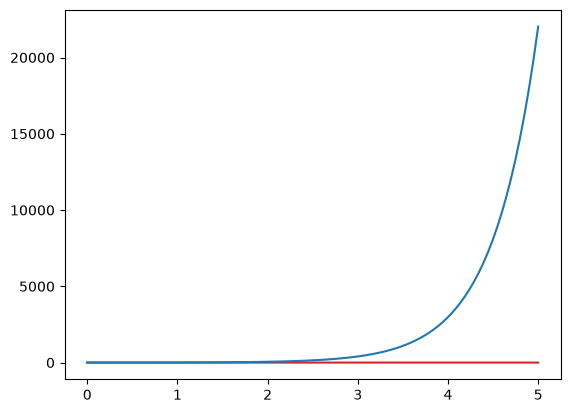

In [23]:
# Votre code ici
X = np.linspace(0, 5, 100)
fig, ax = plt.subplots()

ax.plot(X, np.exp(-X), color="tab:red")
ax.plot(X, np.exp(2*X))
plt.show


<details>
<summary>💡 Voir la solution</summary>

```python
x = np.linspace(0, 5, 100)
fig, ax = plt.subplots()
ax.plot(x, np.exp(-x), color="red", linestyle=":", label="exp(-x)")
ax.plot(x, np.exp(-2 * x), color="blue", label="exp(-2x)")
ax.legend()
plt.show()
```

</details>

### ✏️ Exercice 3

Générez 200 points aléatoires `(x, y)` avec `rng.random(200)` pour chaque coordonnée, et affichez-les avec `scatter` (taille 20, transparence 0.5).

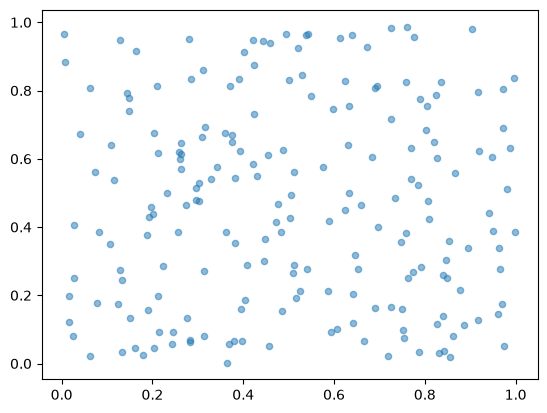

In [24]:
# Votre code ici
rng = np.random.default_rng(1)
X, Y = rng.random(200), rng.random(200)
fig, ax = plt.subplots()
ax.scatter(X, Y, s = 20, alpha = 0.5)

<details>
<summary>💡 Voir la solution</summary>

```python
rng = np.random.default_rng(1)
x = rng.random(200)
y = rng.random(200)
fig, ax = plt.subplots()
ax.scatter(x, y, s=20, alpha=0.5)
plt.show()
```

</details>

### ✏️ Exercice 4

Avec le fichier de températures, tracez l'écart de température entre Marseille et Paris mois par mois. Que constatez-vous ?

<function matplotlib.pyplot.show(close=None, block=None)>

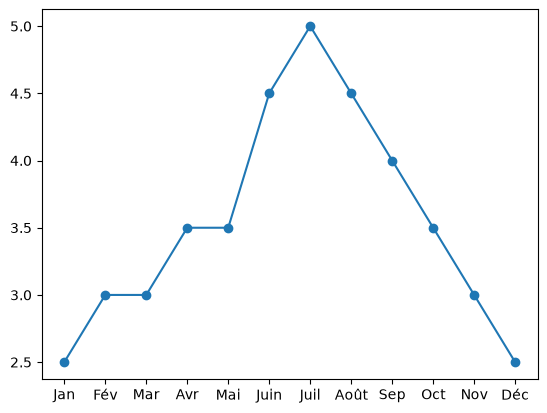

In [25]:
# Votre code ici
temp = pd.read_csv("../data/temperatures.csv")
fig, ax = plt.subplots()
ax.plot(temp["Mois"], temp["Marseille"] - temp["Paris"], marker="o", label=ville)
plt.show


<details>
<summary>💡 Voir la solution</summary>

```python
temp = pd.read_csv("../data/temperatures.csv")
fig, ax = plt.subplots()
ax.plot(temp["Mois"], temp["Marseille"] - temp["Paris"], marker="o")
ax.set_title("Écart Marseille - Paris")
ax.set_ylabel("°C")
plt.show()
```

</details>

### ✏️ Exercice 5

Avec le Titanic, affichez un nuage de points de `SibSp` en fonction de `Parch`... puis constatez pourquoi ce n'est pas lisible (beaucoup de points superposés). Améliorez en ajoutant de la transparence ou en augmentant la taille des points.

In [ ]:
# Votre code ici


<details>
<summary>💡 Voir la solution</summary>

```python
df = pd.read_csv("../data/titanic.csv")
fig, ax = plt.subplots()
ax.scatter(df["Parch"], df["SibSp"], s=200, alpha=0.1)
ax.set_xlabel("Parch")
ax.set_ylabel("SibSp")
plt.show()
```

</details>